# Power control on new layouts

> Predicting the channel well enough to reach a target SNR with a chosen reliability, in layouts the predictor has never seen: what to learn from, how to set the margin, and when to withhold a transmission.

[Power control without channel knowledge](06_predicted_power.ipynb) compares predictors in one fixed room. In an
application, the layout changes from episode to episode and the agents start anywhere, so a predictor has to work in
layouts it has never seen. This example takes the same link, C3-WM's (49 codebook tokens of 8 bits, uncoded BPSK,
channel inversion to a target SNR `Γ`), in ray-traced layouts of MultiGrid's FindGoal, and asks how to set the power
so that a chosen share `1 − ε` of the transmissions reach `Γ`, with as little power as possible:

```text
minimize ρ   subject to   P(SNR(ρ) ≥ Γ) ≥ 1 − ε,   0 ≤ ρ ≤ ρ_max
```

The transmitter does not know the current gain `g = |h|²`. It predicts it (`ĝ`) from what it knows, and sends at
`ρ̂ = κ Γσ²/ĝ`, with a margin `κ` against the prediction's errors. When `ρ̂` exceeds `ρ_max`, it either withholds the
transmission or sends at `ρ_max` anyway.

The questions: what to predict from (the link's past gains, the agents' moves, the layout's geometry, a ray-traced
map), how to set the margin for layouts not seen yet, and when to withhold. Everything is fit on some layouts,
tuned on others, and judged on layouts neither saw.

In [ ]:
import math

import matplotlib.pyplot as plt
import numpy as np
from sklearn.ensemble import HistGradientBoostingRegressor

from comm_core import *

## The layouts

40 layouts of MultiGrid's FindGoal (9 × 9, walls scattered inside), each ray-traced with Sionna RT at 2.4 GHz
(5 bounces) between every pair of free cells. The file holds each pair's gain `|h|²` in dB, the free cells and
the wall grid. It was made with stable-marl's `trace_layouts` (Sionna RT through `trace_paths`), then the gains
converted to dB:

In [ ]:
#| eval: false
from stable_marl.envs.multigrid.sionna_export import trace_layouts

trace_layouts('MultiGrid-FindGoal-15x15-v0', [*range(30), *range(100, 110)], 'layouts',
              env_kwargs=dict(agents=2, size=9, num_obstacles=0), frequency=2.4e9, max_depth=5)

In [ ]:
data = np.load('data/findgoal_layouts.npz')
DIRS = [(1, 0), (0, 1), (-1, 0), (0, -1)]

class Layout:
    "One ray-traced layout: the gain between any two free cells, and the walls between them."
    def __init__(self, k):
        self.seed = int(data['seeds'][k])
        self.cells = [tuple(int(v) for v in c) for c in data['cells'][k]]
        self.idx = {c: i for i, c in enumerate(self.cells)}
        self.G = 10 ** (data['gain_db'][k].astype(float) / 10)               # G[rx, tx]
        self.walls = data['walls'][k]                                       # walls[x, y]

    def gain(self, tx, rx):
        return self.G[self.idx[rx], self.idx[tx]]

    def geometry(self, a, b):
        "Distance (cells) and the number of wall cells the straight line between the two cell centres crosses."
        n = max(int(abs(a[0] - b[0]) + abs(a[1] - b[1])) * 4, 1)
        xs, ys = np.linspace(a[0], b[0], n + 1), np.linspace(a[1], b[1], n + 1)
        crossed = {(int(round(x)), int(round(y))) for x, y in zip(xs, ys)} - {a, b}
        return math.hypot(a[0] - b[0], a[1] - b[1]), int(sum(self.walls[c] for c in crossed))

layouts = {int(s): Layout(k) for k, s in enumerate(data['seeds'])}
FIT, CALIBRATION, TEST = range(0, 24), range(24, 30), range(100, 110)
print(f'{len(layouts)} layouts, {len(layouts[0].cells)} free cells each')

40 layouts, 39 free cells each


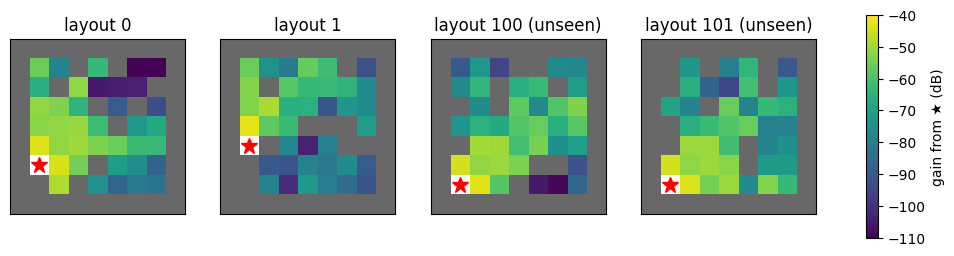

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3.4))
for ax, seed in zip(axes, (0, 1, 100, 101)):
    lay, tx = layouts[seed], layouts[seed].cells[0]
    img = np.full(lay.walls.shape, np.nan)
    for c in lay.cells:
        img[c] = 10 * np.log10(lay.gain(tx, c)) if c != tx else np.nan
    im = ax.imshow(img.T, origin='lower', cmap='viridis', vmin=-110, vmax=-40)
    ax.imshow(np.where(lay.walls.T, 1.0, np.nan), origin='lower', cmap='Greys', vmin=0, vmax=1.5)
    ax.plot(*tx, 'r*', ms=12)
    ax.set(title=f'layout {seed}' + (' (unseen)' if seed >= 100 else ''), xticks=[], yticks=[])
fig.colorbar(im, ax=axes, label='gain from ★ (dB)', shrink=0.85)
plt.show()

## The agents

Two agents move at random, as with a random policy in FindGoal: at each step each one turns left, turns right,
steps forward (unless a wall or the other agent is there) or does nothing. They start in distinct random cells with
random headings. (FindGoal also has a goal, which takes an agent off the grid; there is none here.)

In [ ]:
STEPS, HISTORY, ROLLOUTS = 60, 4, 5

def walk(lay, seed):
    "One episode: per step, both agents' cells and headings."
    rng = np.random.default_rng(seed)
    free = set(lay.cells)
    pos = [lay.cells[k] for k in rng.choice(len(lay.cells), 2, replace=False)]
    head = [int(h) for h in rng.integers(4, size=2)]
    out = []
    for _ in range(STEPS):
        out.append((tuple(pos), tuple(head)))
        for a in rng.permutation(2):
            action = rng.integers(4)                                     # left, right, forward, nothing
            if action < 2:
                head[a] = (head[a] + (1 if action else -1)) % 4
            elif action == 2:
                ahead = (pos[a][0] + DIRS[head[a]][0], pos[a][1] + DIRS[head[a]][1])
                if ahead in free and ahead != pos[1 - a]:
                    pos[a] = ahead
    return out

## What the transmitter knows

For each directed link and step `t ≥ 4`, what transmitter `j` knows when it sends to `i`:

* **The link's last 4 gains,** fed back by the receiver (C3-WM's `x̃`).
* **Whether anyone moved:** the transmitter itself, this step (its own move), and the receiver, a step ago (its
  report arrives with a step's delay, like the gains).
* **Where the receiver was a step ago, and its heading.** Since then, it has stayed or stepped ahead: the
  receiver's *possible cells*.
* **The layout's walls**, for the geometry between the two agents: the distance and the number of walls in between.

Optionally, small-scale fading on top of the ray-traced gain: Rayleigh, redrawn whenever an agent moves (it moves
many wavelengths), and drifting slowly while both stand still.

In [ ]:
db = lambda g: 10 * np.log10(np.maximum(g, 1e-30))

def fading(episode, seed, rho=0.95):
    "|g_t|² of a pair's Rayleigh fading: redrawn when an agent moves, drifting slowly while both stand still."
    rng = np.random.default_rng(10_000 + seed)
    draw = lambda: (rng.standard_normal() + 1j * rng.standard_normal()) / np.sqrt(2)
    g, out = draw(), []
    for t in range(len(episode)):
        if t and episode[t][0] != episode[t - 1][0]:
            g = draw()
        elif t:
            g = rho * g + np.sqrt(1 - rho ** 2) * draw()
        out.append(abs(g) ** 2)
    return np.array(out)

def samples(seeds, faded):
    "Per directed link and step: what the transmitter knows, and the true gain."
    out = []
    for seed in seeds:
        lay = layouts[seed]
        for k in range(ROLLOUTS):
            episode = walk(lay, 1000 * seed + k)
            fade = fading(episode, 1000 * seed + k) if faded else np.ones(len(episode))
            for j, i in ((0, 1), (1, 0)):
                g = [lay.gain(cells[j], cells[i]) * f for (cells, _), f in zip(episode, fade)]
                for t in range(HISTORY, len(episode)):
                    (now, _), (before, heads), (earlier, _) = episode[t], episode[t - 1], episode[t - 2]
                    ahead = (before[i][0] + DIRS[heads[i]][0], before[i][1] + DIRS[heads[i]][1])
                    possible = [c for c in (before[i], ahead) if c in lay.idx and c != now[j]] or [before[i]]
                    out.append(dict(lay=lay, tx=now[j], rx=now[i], possible=possible, past=np.array(g[t - HISTORY:t][::-1]),
                                    moved=[float(now[j] != before[j]), float(before[i] != earlier[i])], gain=g[t]))
    return out

## The predictors

Each predicts the gain `ĝ` of the current transmission:

| predictor | uses | model |
|---|---|---|
| C3-WM's | last 4 gains | linear in `|h|²` (`fit_gain_predictor`, eq. 24) |
| C3-WM's, in dB | last 4 gains | linear in dB (`fit_gain_predictor(..., domain='db')`) |
| history quantile | last 4 gains, moves | gradient-boosted trees, 5% quantile of the gain in dB |
| geometry + history quantile | the same, and the geometry to each possible cell | gradient-boosted trees, 5% quantile; the lowest over the possible cells |
| geometry + history mean | the same | gradient-boosted trees, mean (in dB); the lowest over the possible cells |
| digital twin | a ray-traced map of the layout | the map's lowest gain over the possible cells |

The quantile models predict a gain the true one exceeds 95% of the time: they are cautious by construction. The
geometry models are trained on the receiver's actual cell, and used on each of its possible cells. The digital
twin needs every new layout ray-traced; it is the reference.

In [ ]:
def features(r, cell):
    distance, walls = r['lay'].geometry(r['tx'], cell)
    return [math.log10(max(distance, 0.5)), distance, walls] + list(db(r['past'])) + r['moved']

def lowest(model):
    "The model's prediction for each of the receiver's possible cells: the lowest."
    def predict(rs):
        pairs = [(k, c) for k, r in enumerate(rs) for c in r['possible']]
        out = np.full(len(rs), np.inf)
        np.minimum.at(out, [k for k, _ in pairs], model.predict(np.array([features(rs[k], c) for k, c in pairs])))
        return 10 ** (out / 10)
    return predict

def predictors(fit):
    "name -> predict(samples) -> ĝ; everything learned from `fit` only."
    y = db(np.array([r['gain'] for r in fit]))
    sequences = [np.r_[r['past'][::-1], r['gain']] for r in fit]
    psi, psi_db = fit_gain_predictor(sequences, history=HISTORY), fit_gain_predictor(sequences, history=HISTORY, domain='db')
    trees = lambda **kw: HistGradientBoostingRegressor(max_iter=400, learning_rate=0.05, early_stopping=False, random_state=0, **kw)
    history = lambda rs: np.c_[db(np.stack([r['past'] for r in rs])), [r['moved'] for r in rs]]
    quantile = trees(loss='quantile', quantile=0.05).fit(history(fit), y)
    X = np.array([features(r, r['rx']) for r in fit])
    return {
        "C3-WM's": lambda rs: np.array([max(psi(r['past']), 0.0) for r in rs]),
        "C3-WM's, in dB": lambda rs: np.array([psi_db(r['past']) for r in rs]),
        'history quantile': lambda rs: 10 ** (quantile.predict(history(rs)) / 10),
        'geometry + history quantile': lowest(trees(loss='quantile', quantile=0.05).fit(X, y)),
        'geometry + history mean': lowest(trees(loss='squared_error').fit(X, y)),
        'digital twin': lambda rs: np.array([min(r['lay'].gain(r['tx'], c) for c in r['possible']) for r in rs]),
    }

## Judging a predictor

A transmission is *servable* if perfect CSI could deliver it: its gain is at least `g_min = Γσ²/ρ_max`. A predictor is
judged by two numbers:

* **Reliability:** the share of the servable transmissions that reach `Γ`.
* **Power:** the mean transmit power, relative to perfect CSI's, which spends exactly `Γσ²/g` on each servable
  transmission and nothing on the others.

Only high targets (95% and 99%) are compared: at lower ones, a predictor can look cheap by giving up the weakest
links, which take most of the power.

Each predictor is deployed with a margin `κ`, `ρ̂ = 10^(κ/10) Γσ²/ĝ`, and a scheduling threshold `τ`: the transmission
is sent if `ρ̂ ≤ 10^(τ/10) ρ_max`, at `min(ρ̂, ρ_max)`, and withheld otherwise. `τ = 0` is C3-WM's rule
(`δ = 1(ρ̂ ≤ ρ_max)`); `τ = ∞` never withholds (best effort). `κ`, and `τ` when it is tuned, are chosen on
calibration layouts: the cheapest pair that reaches the target there. The link budget: `Γ = 10 dB`,
`σ² = −94 dBm`, `ρ_max = 20 dBm`.

In [ ]:
SNR_TARGET_DB, NOISE_DBM, MAX_POWER_DBM = 10.0, -94.0, 20.0
G_MIN = 10 ** ((SNR_TARGET_DB + NOISE_DBM - MAX_POWER_DBM) / 10)      # Γσ²/ρ_max
MARGINS = np.arange(-10, 40.01, 0.25)                                 # κ, dB
TAUS = (0.0, 1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 20, 25, 30, math.inf)    # τ, dB
print(f'g_min = {db(G_MIN):.0f} dB')

def outcome(estimate, gain, g_min=G_MIN, tau=0.0):
    """Per margin κ: the share of the servable transmissions reaching Γ, the mean power (× perfect CSI's), the share
    withheld, and the per-transmission power (in units of Γσ²). τ: withhold when ρ̂ > τ ρ_max (dB); inf: never."""
    max_power, servable, need = 1 / g_min, gain >= g_min, 1 / gain
    rho = 10 ** (MARGINS[:, None] / 10) / np.maximum(estimate, 1e-30)[None, :]
    sent = rho <= max_power * 10 ** (tau / 10) if np.isfinite(tau) else np.ones_like(rho, bool)
    power = np.where(sent, np.minimum(rho, max_power), 0)
    reached = sent & (power >= need * (1 - 1e-9))
    perfect = np.where(servable, need, 0).mean()
    return reached[:, servable].mean(1), power.mean(1) / perfect, 1 - sent.mean(1), power

def deploy(name, faded, target, g_min=G_MIN, taus=(0.0,)):
    """κ (and τ, from `taus`) chosen on the calibration layouts, the cheapest reaching `target` there (else the most
    reliable); then used on the unseen layouts."""
    (cal, cal_gain), (test, test_gain) = runs[faded][name]
    best = None
    for tau in taus:
        reached, power, _, _ = outcome(cal, cal_gain, g_min, tau)
        for k in range(len(MARGINS)):
            key = (reached[k] >= target, -power[k] if reached[k] >= target else reached[k])
            if best is None or key > best[0]:
                best = (key, tau, k)
    (met, _), tau, k = best
    reached, power, withheld, per_transmission = outcome(test, test_gain, g_min, tau)
    return dict(reached=reached[k], power=power[k], withheld=withheld[k], margin=MARGINS[k], tau=tau, met=met,
                per_transmission=per_transmission[k])

g_min = -104 dB


## On new layouts

The models are fit on layouts 0–23, the margins are chosen on layouts 24–29, and everything is judged on
layouts 100–109, which neither saw. Without fading, then with it:

In [ ]:
runs = {}
for faded in (False, True):
    fit, cal, test = samples(FIT, faded), samples(CALIBRATION, faded), samples(TEST, faded)
    gains = lambda rs: np.array([r['gain'] for r in rs])
    runs[faded] = {name: ((p(cal), gains(cal)), (p(test), gains(test))) for name, p in predictors(fit).items()}
    print(f"{'Rayleigh fading' if faded else 'no fading'}: {len(fit)} / {len(cal)} / {len(test)} transmissions "
          f"(fit / calibration / unseen); {100 * (gains(test) >= G_MIN).mean():.1f}% of the unseen ones servable")

no fading: 13440 / 3360 / 5600 transmissions (fit / calibration / unseen); 93.7% of the unseen ones servable


Rayleigh fading: 13440 / 3360 / 5600 transmissions (fit / calibration / unseen); 91.9% of the unseen ones servable


In [ ]:
def table(faded, rules=(((0.0,), 'withhold (τ = 0)'), ((math.inf,), 'best effort (τ = ∞)'), (TAUS, 'tuned τ')), targets=(0.95, 0.99)):
    print(f"{'Rayleigh fading' if faded else 'no fading'}: reliability reached on the unseen layouts, "
          f"power (× perfect CSI); ✗: target not reached on the calibration layouts")
    print(f"{'':28s}" + ''.join(f'{label:>34s}' for _, label in rules))
    print(f"{'':28s}" + ''.join(f'{100 * t:>16.0f}%' for _ in rules for t in targets))
    for name in runs[faded]:
        row = [deploy(name, faded, t, taus=taus) for taus, _ in rules for t in targets]
        print(f'{name:28s}' + ''.join(f"{100 * d['reached']:8.1f}% {d['power']:5.1f}×{' ' if d['met'] else '✗'}" for d in row))

table(False)
print()
table(True)

no fading: reliability reached on the unseen layouts, power (× perfect CSI); ✗: target not reached on the calibration layouts
                                              withhold (τ = 0)               best effort (τ = ∞)                           tuned τ
                                          95%              99%              95%              99%              95%              99%


C3-WM's                         96.6%   6.1×     98.1%  13.7×✗    96.5%   5.2×     98.2%  13.8×✗    96.5%   5.2×     98.2%  13.8×✗


C3-WM's, in dB                  87.9%   1.6×✗    87.9%   1.6×✗    95.0%   4.5×     99.2%  10.1×     94.7%   3.2×     99.1%   9.8× 


history quantile                89.9%   1.1×✗    89.9%   1.1×✗    95.4%   4.4×     98.9%   8.2×     94.8%   3.7×     98.9%   8.2× 


geometry + history quantile     92.2%   1.3×✗    92.2%   1.3×✗    94.9%   4.0×     99.0%   6.8×     94.4%   2.0×     99.0%   6.8× 


...

C3-WM's, in dB                  86.8%   1.6×✗    86.8%   1.6×✗    95.4%   6.1×     99.3%  12.3×     95.4%   5.1×     99.2%  12.5× 


history quantile                85.9%   1.6×✗    85.9%   1.6×✗    95.2%   6.1×     99.0%  10.7×     95.2%   5.2×     99.0%  10.7× 


geometry + history quantile     86.6%   1.5×✗    86.6%   1.5×✗    94.8%   5.7×     99.2%   9.5×     94.5%   4.2×     99.2%   9.5× 


geometry + history mean         87.2%   1.7×✗    87.2%   1.7×✗    95.3%   5.7×     99.3%  10.5×     94.9%   4.1×     99.2%   9.9× 


digital twin                    84.4%   1.7×✗    84.4%   1.7×✗    94.8%   6.5×     99.2%   9.7×     94.5%   5.0×     99.2%   9.8× 


* **C3-WM's predictor can't be made reliable.** Fit on `|h|²`, it overestimates weak links (the fit is dominated by
  the strong ones), and a margin can't fix an error that depends on the link's strength: it never reaches 99%.
  Fit in dB, the same linear predictor is unbiased, and reaches both targets.
* **Withholding as soon as `ρ̂ > ρ_max` (`τ = 0`) caps the reliability of a cautious predictor.** None of the
  learned ones reaches 95% that way, except C3-WM's fit on `|h|²` without fading, which rarely predicts more than
  `ρ_max` (it is optimistic about weak links, and fails them instead). The margin that rescues underestimated
  transmissions also pushes others over `ρ_max`, where they are withheld although they would have succeeded.
* **The margins transfer.** Chosen on 6 layouts, they land within 0.7 percentage points of the target on the 10
  unseen ones.
* **The layout's geometry helps.** At 99% without fading, the geometry + history quantile needs 6.8× perfect CSI's
  power, the history alone 8.2×, C3-WM's in dB 9.8×.
* **Fading levels the field.** With fading, every predictor needs 10–12× for 99%, the digital twin included:
  the fading is redrawn whenever an agent moves, so no one can predict it, and its unpredictable part sets the cost.
  Without fading, the digital twin's map is exact and it needs 1.5×.
* **Tuning `τ` pays at 95%** (2.0× instead of 4.0× for the geometry model without fading). At 99%, the tuned `τ`
  is large or infinite, and the power within 6% of best effort's: to lose only 1%, little can be withheld.

## The link budget

`Γ`, `σ²` and `ρ_max` matter only through `g_min = Γσ²/ρ_max`, the weakest gain a link can have and still be
served: raising `Γ` by 3 dB is the same as lowering `ρ_max` by 3 dB. The power each predictor needs for 99%, with
the threshold `τ` tuned, from a tight budget (left) to a loose one:

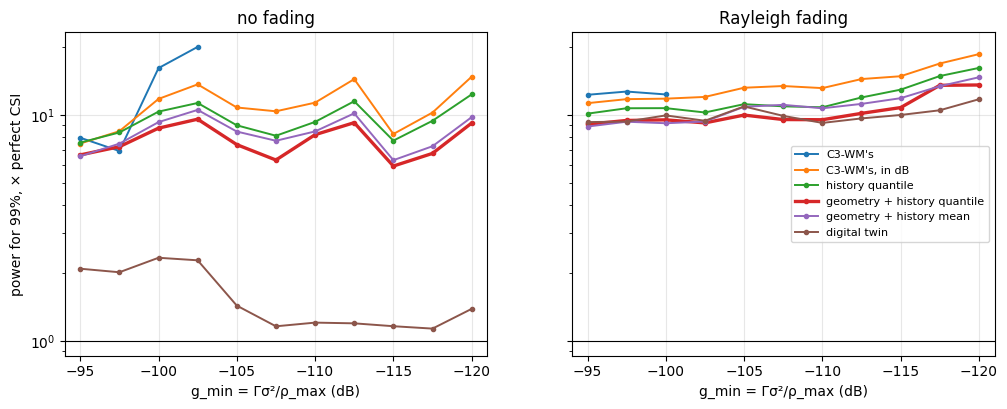

In [ ]:
G_SWEEP_DB = np.arange(-95, -120.1, -2.5)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, faded in zip(axes, (False, True)):
    for name in runs[faded]:
        power = [deploy(name, faded, 0.99, 10 ** (g / 10), taus=TAUS) for g in G_SWEEP_DB]
        ax.plot(G_SWEEP_DB, [d['power'] if d['met'] else np.nan for d in power], 'o-', ms=3,
                lw=2.4 if name == 'geometry + history quantile' else 1.4, label=name)
    ax.axhline(1, color='k', lw=0.8)
    ax.set(title='Rayleigh fading' if faded else 'no fading', xlabel='g_min = Γσ²/ρ_max (dB)', yscale='log',
           xlim=(G_SWEEP_DB[0] + 1, G_SWEEP_DB[-1] - 1))
    ax.grid(alpha=0.3)
axes[0].set_ylabel('power for 99%, × perfect CSI')
axes[1].legend(fontsize=8)
plt.show()

Without fading, the learned predictors (C3-WM's aside) need 6–15× perfect CSI's power for 99%, and the digital twin
1.1–2.3×. With fading, all of them need 9–18×, and the twin's advantage is gone. C3-WM's predictor reaches 99% only on
the tightest budgets, where the weak links it overestimates are not servable anyway. The geometry + history models
are the cheapest learned ones over the whole range.

## What the agents receive

Reaching `Γ` is not the same as arriving intact. A message is 49 tokens of 8 bits over uncoded BPSK, so at the
SNR it gets, each bit is wrong with probability `Q(√(2 SNR))`. With the margins chosen above, the share of the
servable messages that arrive with no bit error, and the share of wrong tokens in those sent, for two
targets `Γ` (at the same `g_min`, so with `ρ_max` scaled along: the reliability results above don't change):

In [ ]:
erfc = np.vectorize(math.erfc)
TOKENS, BITS = 49, 8

def received(power, gain, snr_target_db):
    "(error-free share of the servable messages, wrong-token share in the servable messages sent)."
    servable, sent = gain >= G_MIN, power > 0
    ber = 0.5 * erfc(np.sqrt(10 ** (snr_target_db / 10) * power * gain))
    clean = np.where(sent, (1 - ber) ** (TOKENS * BITS), 0)[servable].mean()
    return clean, (1 - (1 - ber[sent & servable]) ** BITS).mean()

for faded in (False, True):
    gain = runs[faded]['digital twin'][1][1]
    print(f"{'Rayleigh fading' if faded else 'no fading'}, tuned τ, target 99%:   error-free / wrong tokens")
    print(f"{'':28s}{'Γ = 7 dB':>22s}{'Γ = 10 dB':>22s}")
    exact = np.where(gain >= G_MIN, 1 / gain, 0)
    print(f"{'perfect CSI (exactly Γ)':28s}" + ''.join(f'{100 * c:12.1f}% {100 * w:6.2f}%  ' for c, w in (received(exact, gain, s) for s in (7, 10))))
    for name in runs[faded]:
        d = deploy(name, faded, 0.99, taus=TAUS)
        print(f'{name:28s}' + ''.join(f'{100 * c:12.1f}% {100 * w:6.2f}%  ' for c, w in (received(d["per_transmission"], gain, s) for s in (7, 10))))
    print()

no fading, tuned τ, target 99%:   error-free / wrong tokens
                                          Γ = 7 dB             Γ = 10 dB
perfect CSI (exactly Γ)             73.9%   0.62%          99.8%   0.00%  
C3-WM's                             99.0%   0.03%         100.0%   0.00%  
C3-WM's, in dB                      98.9%   0.16%          99.4%   0.08%  


history quantile                    98.9%   0.35%          99.5%   0.22%  
geometry + history quantile         99.0%   0.24%          99.5%   0.10%  


geometry + history mean             98.8%   0.22%          99.4%   0.10%  
digital twin                        79.4%   0.46%          98.8%   0.00%  

Rayleigh fading, tuned τ, target 99%:   error-free / wrong tokens
                                          Γ = 7 dB             Γ = 10 dB
perfect CSI (exactly Γ)             73.9%   0.62%          99.8%   0.00%  


C3-WM's                             97.8%   0.12%          99.8%   0.01%  
C3-WM's, in dB                      99.1%   0.15%          99.4%   0.08%  


history quantile                    99.0%   0.32%          99.5%   0.21%  
geometry + history quantile         99.2%   0.14%          99.7%   0.04%  


geometry + history mean             99.1%   0.13%          99.5%   0.06%  
digital twin                        99.1%   0.11%          99.4%   0.04%  



* **At `Γ = 7 dB`, reaching `Γ` is not arriving intact.** Even perfect CSI delivers only 74% of the messages without
  a bit error: at exactly `Γ`, a bit is wrong with probability `8·10⁻⁴`, and a message has 392 of them. The
  learned predictors deliver about 99% error-free, because their margins put most transmissions well above `Γ`.
  The digital twin without fading, accurate and with little margin, delivers 79%.
* **At `Γ = 10 dB`, the two agree.** Perfect CSI delivers 99.8% error-free, every predictor about its reliability,
  and under 0.25% of the tokens are wrong.

So `Γ` belongs to the message: about 10 dB makes "reaching `Γ`" mean "arriving intact" for 392 uncoded bits. The
reliability and power results above don't depend on it, only on `g_min`.

## When to withhold a transmission

C3-WM withholds a transmission when its predicted power exceeds the budget (`δ = 1(ρ̂ ≤ ρ_max)`); best effort never
does, and sends at `ρ_max`. Between the two, a threshold `τ`: withhold only when `ρ̂ > τ ρ_max`, otherwise send at
`min(ρ̂, ρ_max)`. Here `τ` is chosen on the calibration layouts together with the margin, the cheapest pair
reaching the target:

In [ ]:
name = 'geometry + history quantile'
for faded in (False, True):
    print(f"{name}, {'Rayleigh fading' if faded else 'no fading'}: reliability / power (× perfect CSI) / withheld")
    print(f"{'g_min':>8s}{'target':>8s}{'withhold (τ = 0)':>27s}{'best effort (τ = ∞)':>27s}{'tuned τ':>38s}")
    for g in (-95, -100, -104):
        for target in (0.95, 0.99):
            row = [deploy(name, faded, target, 10 ** (g / 10), taus=t) for t in ((0.0,), (math.inf,), TAUS)]
            cells = [f"{100 * d['reached']:6.1f}% {d['power']:5.1f}× {100 * d['withheld']:4.1f}%{' ' if d['met'] else '✗'}" for d in row]
            tau = row[2]['tau']
            print(f'{g:5d} dB{100 * target:7.0f}%' + ''.join(f'{c:>27s}' for c in cells[:2]) + f"{'τ = ' + ('∞' if math.isinf(tau) else f'{tau:g} dB'):>14s}{cells[2]:>24s}")
    print()

geometry + history quantile, no fading: reliability / power (× perfect CSI) / withheld
   g_min  target           withhold (τ = 0)        best effort (τ = ∞)                               tuned τ


  -95 dB     95%        88.3%   1.3× 18.5%✗        95.4%   4.5×  0.0%       τ = 6 dB     94.6%   2.6× 12.2% 


  -95 dB     99%        88.3%   1.3× 18.5%✗        99.2%   6.7×  0.0%          τ = ∞     99.2%   6.7×  0.0% 


 -100 dB     95%        92.4%   1.9× 13.2%✗        94.6%   5.4×  0.0%       τ = 8 dB     94.8%   3.2×  7.9% 


 -100 dB     99%        92.4%   1.9× 13.2%✗        99.1%   8.7×  0.0%          τ = ∞     99.1%   8.7×  0.0% 


...

  -95 dB     99%        81.9%   1.3× 25.4%✗        99.2%   9.1×  0.0%          τ = ∞     99.2%   9.1×  0.0% 


 -100 dB     95%        84.5%   1.4× 19.3%✗        94.8%   6.0×  0.0%      τ = 12 dB     94.5%   4.3×  9.7% 


 -100 dB     99%        84.5%   1.4× 19.3%✗        99.3%   9.5×  0.0%          τ = ∞     99.3%   9.5×  0.0% 


 -104 dB     95%        86.6%   1.5× 15.2%✗        94.8%   5.7×  0.0%      τ = 10 dB     94.5%   4.2×  8.6% 


 -104 dB     99%        86.6%   1.5× 15.2%✗        99.2%   9.5×  0.0%          τ = ∞     99.2%   9.5×  0.0% 



* **At 95%, a tuned threshold saves power.** With `τ` between 6 and 15 dB, the transmitter withholds the 7–12% of
  transmissions predicted far beyond the budget, and spends half of best effort's power without fading (2.0–3.2×
  instead of 4.0–5.4×), and a quarter less with fading (4.2–4.4× instead of 5.7–6.1×).
* **At 99%, it is best effort:** `τ = ∞` on every budget. To lose only 1%, no transmission can be withheld.
* **Withholding at `ρ̂ > ρ_max` (`τ = 0`)** reaches 82–92% at most.
* **Tuned on 6 layouts, `τ` slightly undershoots on new ones** (94.4–94.8% for a 95% target). If the target must
  hold, tune for a slightly higher one, or keep `τ` above a few dB.

## The same through a network

The learned predictor as a comm-core power control: `LearnedChannelInversion` keeps each link's past gains (known
after each transmission, as the receiver feeds them back), notes where the nodes are at every round (the receiver's
cell and heading reach the transmitter a round late), and allocates with the margin and threshold chosen above
for 99%.
Here it runs through a `LinkLevelChannel`, every bit of every message, on the unseen layouts without fading:

In [ ]:
class LearnedChannelInversion(PowerControl):
    "Channel inversion with a learned gain prediction (`features` -> dB), the lowest over the receiver's possible cells."

    def __init__(self, model, layout, fading, headings, target_snr_db, max_power, margin_db=0.0, tau_db=math.inf):
        self.model, self.layout, self.fading, self.headings = model, layout, fading, headings
        self.target_snr_db, self.max_power, self.margin_db, self.tau_db = target_snr_db, max_power, margin_db, tau_db
        self.reset()

    def reset(self, seed=None):
        self._past, self._rounds = {}, []

    def update(self, time):
        "A new round: where the nodes are now, and their headings; the last rounds are what they reported."
        self._rounds = (self._rounds + [(dict(self.fading.node_positions), dict(self.headings()))])[-3:]

    def allocate(self, gain, noise_power, link=None, message=None):
        past = self._past.setdefault((link.sender, link.receiver), [])
        if len(past) < HISTORY or len(self._rounds) < 3:
            power, send = self.max_power, True                          # not enough history yet: full power
        else:
            (earlier, _), (before, heads), (now, _) = self._rounds
            tx, rx = now[link.sender], before[link.receiver]
            d = DIRS[heads[link.receiver]]
            possible = [c for c in (rx, (rx[0] + d[0], rx[1] + d[1])) if c in self.layout.idx and c != tx] or [rx]
            r = dict(lay=self.layout, tx=tx, past=np.array(past[-HISTORY:][::-1]),
                     moved=[float(tx != before[link.sender]), float(rx != earlier[link.receiver])])
            predicted = 10 ** (min(self.model.predict(np.array([features(r, c) for c in possible]))) / 10)
            rho = 10 ** ((self.target_snr_db + self.margin_db) / 10) * noise_power / predicted
            power, send = min(rho, self.max_power), rho <= self.max_power * 10 ** (self.tau_db / 10)
        past.append(float(gain))                                        # fed back after the transmission
        return power, send

In [ ]:
fit = samples(FIT, False)
model = HistGradientBoostingRegressor(loss='quantile', quantile=0.05, max_iter=400, learning_rate=0.05, early_stopping=False,
                                      random_state=0).fit(np.array([features(r, r['rx']) for r in fit]), db(np.array([r['gain'] for r in fit])))
chosen = deploy('geometry + history quantile', False, 0.99, taus=TAUS)
NOISE_W, MAX_POWER_W = 10 ** ((NOISE_DBM - 30) / 10), 10 ** ((MAX_POWER_DBM - 30) / 10)
AGENTS = ['agent_0', 'agent_1']
tokens = np.random.default_rng(0).integers(256, size=49)

reached, power, perfect, clean = [], [], [], []
for seed in TEST:
    lay = layouts[seed]
    for k in range(ROLLOUTS):
        episode = walk(lay, 1000 * seed + k)
        fading_map = RayTracedFading(np.sqrt(lay.G).astype(complex), lay.cells)
        heads = {}
        control = LearnedChannelInversion(model, lay, fading_map, lambda: heads, SNR_TARGET_DB, MAX_POWER_W,
                                          margin_db=chosen['margin'], tau_db=chosen['tau'])
        channel = LinkLevelChannel(codec=IndexCodec(256), fading=fading_map, power_control=control, noise_power=NOISE_W, seed=k)
        net = Network([Node(a) for a in AGENTS], FullMeshTopology(AGENTS), IdealProtocol(), AnalyticalBackend(channel))
        net.reset(seed=seed)
        for t, (cells, headings) in enumerate(episode):
            channel.set_positions(dict(zip(AGENTS, cells)))
            heads.update(zip(AGENTS, headings))
            for a, b in ((0, 1), (1, 0)):
                net.send(Message(AGENTS[a], AGENTS[b], payload=tokens))
            for r in net.step():
                if t < HISTORY:
                    continue
                g, p = 10 ** (r.metadata['channel_gain_db'] / 10), r.metadata['tx_power']
                servable = g >= G_MIN
                power.append(p)                                          # spent on every link, servable or not
                perfect.append(10 ** (SNR_TARGET_DB / 10) * NOISE_W / g if servable else 0.0)
                if servable:
                    reached.append(p * g / NOISE_W >= 10 ** (SNR_TARGET_DB / 10) * (1 - 1e-9))
                    clean.append(not r.metadata.get('outage') and r.metadata.get('bit_errors', 1) == 0)

tau = '∞' if math.isinf(chosen['tau']) else f"{chosen['tau']:g} dB"
print(f"margin {chosen['margin']:+.2f} dB, τ = {tau}; servable transmissions: {len(reached)} of {len(power)}")
print(f"{'':12s}{'reached Γ':>12s}{'power':>10s}{'error-free':>13s}")
print(f"{'network':12s}{100 * np.mean(reached):11.1f}%{np.mean(power) / np.mean(perfect):9.1f}×{100 * np.mean(clean):12.1f}%")
print(f"{'analysis':12s}{100 * chosen['reached']:11.1f}%{chosen['power']:9.1f}×")

margin +7.75 dB, τ = ∞; servable transmissions: 5248 of 5600
               reached Γ     power   error-free
network            99.0%      6.8×        99.6%
analysis           99.0%      6.8×


The network reaches `Γ` on the same share of the servable transmissions, with the same power, as the analysis: the
analysis computes what `LearnedChannelInversion` does. Through every bit, 99.6% of the servable messages arrive
without an error.

The power control needs, besides the model: each link's past gains (fed back by the receiver), the nodes' cells and
headings, a round late for the receiver (`update` notes them), and the layout's walls. All of these are
application knowledge that comm-core is given, never tracks itself.

## In short

* **Predict the gain from the link's history, the agents' moves and the layout's geometry.** These models are the
  cheapest learned predictors in every setting here (the low quantile slightly ahead of the mean at 99%), and they
  need no ray tracing at run time. Without the layout, the history alone (with the moves) comes next.
* **Choose the margin, and the scheduling threshold, on held-out layouts.** They transfer to new ones within 0.7
  percentage points of the target.
* **Don't withhold as soon as `ρ̂ > ρ_max`.** For 95%, withhold only far beyond it (`τ` ≈ 6–15 dB here); for 99%,
  never.
* **With fading, its unpredictable part sets the cost** (about 10× perfect CSI's power for 99%), and a ray-traced
  map no longer helps. Without fading, a map of each layout (a digital twin) is far cheaper, if every layout can be
  ray-traced.
* **Pick `Γ` so that reaching it means arriving intact:** about 10 dB for 392 uncoded bits.

The numbers depend on the setting: random moves (a learned policy moves differently), FindGoal's open layouts, and
Rayleigh fading (the worst case; a line-of-sight component makes fading milder).

In [ ]:
tuned = {(f, name): deploy(name, f, 0.99, taus=TAUS) for f in (False, True) for name in runs[f]}
assert all(d['reached'] > 0.985 for (f, name), d in tuned.items() if name != "C3-WM's")       # the margins transfer
assert not any(tuned[f, "C3-WM's"]['met'] for f in (False, True))                             # the bias, which no margin fixes
assert not any(deploy(name, True, 0.99)['met'] for name in runs[True])                        # withholding (τ = 0) falls short
assert tuned[False, 'geometry + history quantile']['power'] < tuned[False, 'history quantile']['power']
assert abs(np.mean(reached) - chosen['reached']) < 0.01 and abs(np.mean(power) / np.mean(perfect) - chosen['power']) < 0.1 * chosen['power']